<div style="width: 100%; clear: both;">
  <div style="float: left; width: 50%;">
    <img src="https://www.ucc.edu.co/institucional/acerca-de-la-universidad/Documents/logo_ucc_2018(CURVAS)-01.png" align="left" style="max-width: 100%; height: auto;">
  </div>
  <div style="float: right; width: 50%;">
    <p style="margin: 0; text-align:right;">Universidad Cooperativa de Colombia</p>
    <p style="margin: 0; text-align:right;">Campus Ibagué-Espinal · Facultad de Ingeniería</p>
    <p style="margin: 0; text-align:right; padding-bottom: 80px;">Programa de Ingeniería de Sistemas</p>
  </div>
</div>
<div style="width:100%;">&nbsp;</div>

<div style="font-size: 22px; font-weight: bold; background: linear-gradient(to right, #ff7e5f, #feb47b); -webkit-background-clip: text; color: grey; text-align: center">
Clasificación de Enfermedades en Hojas de Plantas<br>
<span style="font-size:16px">Pipeline + 10+ Clases Propias + Transfer Learning + Knowledge Distillation + Grad-CAM + App</span>
</div>

<div style="text-align:center; color:#666; margin-top:10px;">
Electiva III · Validación de Trabajo Previo · Cumple EJE 1, 2, 3 y 4
</div>

---
# 1. Visión general y cumplimiento de requisitos

| Eje | Requisito | Cómo se cumple en este notebook |
|-----|-----------|----------------------------------|
| **EJE 1** | ≥10 clases propias + 300-500 img/clase + script de ingesta | Detecta automáticamente todas las carpetas (PlantVillage + clases propias). Pipeline completo de limpieza, RGB, eliminación de corruptas/duplicadas. |
| **EJE 2** | Arquitectura reconocida + 50 épocas + EarlyStopping + Dropout + Acc ≥94% | MobileNetV2 / EfficientNetB0 / ResNet50V2. epochs=50, patience=9, Dropout 0.3-0.5. |
| **EJE 3** | Knowledge Distillation + Grad-CAM | Teacher (EfficientNetB0) → Student (MobileNetV2). Grad-CAM implementado. |
| **EJE 4** | App interactiva (Streamlit/Gradio) | Se genera `app.py` listo para ejecutar. |

---
# 2. Configuración del entorno y verificación GPU

In [2]:
import sys
print("Python:", sys.version)

import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

# Configurar crecimiento de memoria GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("✅ GPU configurada correctamente (memory growth activado)")
    except RuntimeError as e:
        print(e)
else:
    print("⚠️ No se detectó GPU. El entrenamiento será más lento.")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import shutil
import time
import json
import hashlib
import random
from pathlib import Path
from tqdm import tqdm
from collections import Counter

from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, ResNet50V2
from tensorflow.keras import layers, models, optimizers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.models import load_model
from tensorflow.keras import backend as K

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
print("\n✅ Todas las librerías se cargaron correctamente.")

Python: 3.14.4 (main, Aug 20 2026, 10:41:58) [GCC 15.2.0]
TensorFlow: 2.22.0-rc0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU configurada correctamente (memory growth activado)

✅ Todas las librerías se cargaron correctamente.


---
# 3. Rutas y parámetros globales

**Importante:** Este notebook debe ejecutarse con el directorio de trabajo en:
`/mnt/c/Users/juanp/Videos/Electiva 3/PlantVillage`

(Es decir, la carpeta que contiene tanto las clases originales como las nuevas).

In [3]:
# ==================== RUTAS ====================
BASE_DIR = Path(".").resolve()
DATA_RAW = BASE_DIR                          # Carpeta actual (contiene todas las clases)
DATA_PROCESSED = BASE_DIR / "data" / "processed"
DATA_FINAL = BASE_DIR / "data" / "final"     # train / val / test
MODELS_DIR = BASE_DIR / "modelos_plantvillage"
RESULTS_DIR = BASE_DIR / "resultados_plantvillage"

for d in [DATA_PROCESSED, DATA_FINAL, MODELS_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ==================== PARÁMETROS ====================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
BLUR_THRESHOLD = 80          # Umbral de nitidez (Laplacian variance)
RANDOM_SEED = 42
MIN_IMAGES_PER_CLASS = 50    # Mínimo para no descartar clase (ajustar según tengas)

# Entrenamiento (cumple EJE 2)
EPOCHS = 50                  # Obligatorio ≥ 50
PATIENCE = 9                 # EarlyStopping (8-10)
DROPOUT_RATE = 0.4           # Entre 0.2 y 0.5

print("📂 Rutas configuradas:")
print(f"   Base          : {BASE_DIR}")
print(f"   Procesado     : {DATA_PROCESSED}")
print(f"   Final         : {DATA_FINAL}")
print(f"   Modelos       : {MODELS_DIR}")
print(f"   Resultados    : {RESULTS_DIR}")
print(f"\n⚙️  Épocas: {EPOCHS} | Patience: {PATIENCE} | Dropout: {DROPOUT_RATE}")

📂 Rutas configuradas:
   Base          : /mnt/c/Users/juanp/Videos/Electiva 3/PlantVillage
   Procesado     : /mnt/c/Users/juanp/Videos/Electiva 3/PlantVillage/data/processed
   Final         : /mnt/c/Users/juanp/Videos/Electiva 3/PlantVillage/data/final
   Modelos       : /mnt/c/Users/juanp/Videos/Electiva 3/PlantVillage/modelos_plantvillage
   Resultados    : /mnt/c/Users/juanp/Videos/Electiva 3/PlantVillage/resultados_plantvillage

⚙️  Épocas: 50 | Patience: 9 | Dropout: 0.4


---
# 4. EJE 1 – Pipeline de Ingeniería de Datos

Este bloque realiza de forma **reproducible**:
1. Detección automática de todas las clases (carpetas).
2. Verificación de integridad (imágenes corruptas).
3. Eliminación de duplicados (por hash MD5).
4. Conversión a RGB y redimensionado.
5. Filtrado de imágenes borrosas.
6. Estructuración en `data/processed/`.

In [4]:
def es_imagen_valida(ruta):
    """Verifica que la imagen se pueda abrir y no esté corrupta."""
    try:
        img = cv2.imread(str(ruta))
        if img is None:
            return False
        if img.shape[0] < 32 or img.shape[1] < 32:
            return False
        return True
    except:
        return False

def calcular_hash(ruta):
    """Hash MD5 para detectar duplicados."""
    hasher = hashlib.md5()
    with open(ruta, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b''):
            hasher.update(chunk)
    return hasher.hexdigest()

def es_nitida(ruta, threshold=BLUR_THRESHOLD):
    """Filtra imágenes muy borrosas usando varianza del Laplaciano."""
    img = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return False
    return cv2.Laplacian(img, cv2.CV_64F).var() >= threshold

def procesar_dataset(raw_dir, processed_dir, min_images=MIN_IMAGES_PER_CLASS):
    """
    Pipeline completo de ingeniería de datos (EJE 1).
    - Detecta todas las carpetas como clases
    - Elimina corruptas y duplicadas
    - Convierte a RGB y redimensiona
    - Filtra borrosas
    - Guarda en data/processed/
    """
    raw_dir = Path(raw_dir)
    processed_dir = Path(processed_dir)

    # Carpetas a ignorar (no son clases)
    ignorar = {
        'data', 'dataset_procesado', 'dataset_final', 'modelos_plantvillage',
        'resultados_plantvillage', 'PlantVillage', '.ipynb_checkpoints',
        '__pycache__', 'modelos', 'resultados'
    }

    # Detectar clases (carpetas de primer nivel)
    clases = [d for d in raw_dir.iterdir()
              if d.is_dir() and d.name not in ignorar and not d.name.startswith('.')]

    print(f"🔍 Clases detectadas: {len(clases)}")
    for c in sorted(clases):
        print(f"   • {c.name}")

    estadisticas = {}
    hashes_globales = {}

    for clase_dir in tqdm(clases, desc="Procesando clases"):
        nombre_clase = clase_dir.name
        dest_dir = processed_dir / nombre_clase
        dest_dir.mkdir(parents=True, exist_ok=True)

        imagenes = list(clase_dir.rglob("*"))
        imagenes = [f for f in imagenes if f.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}]

        validas = 0
        corruptas = 0
        duplicadas = 0
        borrosas = 0

        for img_path in imagenes:
            # 1. Integridad
            if not es_imagen_valida(img_path):
                corruptas += 1
                continue

            # 2. Duplicados
            h = calcular_hash(img_path)
            if h in hashes_globales:
                duplicadas += 1
                continue
            hashes_globales[h] = img_path

            # 3. Nitidez
            if not es_nitida(img_path):
                borrosas += 1
                continue

            # 4. Cargar, convertir a RGB y redimensionar
            img = cv2.imread(str(img_path))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

            # Guardar
            dest_path = dest_dir / f"{nombre_clase}_{validas:05d}.jpg"
            cv2.imwrite(str(dest_path), cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])
            validas += 1

        estadisticas[nombre_clase] = {
            "validas": validas,
            "corruptas": corruptas,
            "duplicadas": duplicadas,
            "borrosas": borrosas,
            "total_original": len(imagenes)
        }

    # Resumen
    print("\n📊 RESUMEN DE PROCESAMIENTO")
    print("-" * 70)
    df_stats = pd.DataFrame(estadisticas).T
    df_stats = df_stats.sort_values("validas", ascending=False)
    print(df_stats.to_string())
    print("-" * 70)
    print(f"Total imágenes válidas: {df_stats['validas'].sum()}")

    # Filtrar clases con muy pocas imágenes
    clases_finales = [c for c, s in estadisticas.items() if s["validas"] >= min_images]
    print(f"\n✅ Clases que cumplen mínimo de {min_images} imágenes: {len(clases_finales)}")

    return estadisticas, clases_finales

# Ejecutar solo si no existe ya el dataset procesado
if not any(DATA_PROCESSED.iterdir()):
    print("🚀 Iniciando pipeline de ingeniería de datos (EJE 1)...\n")
    stats, CLASS_NAMES = procesar_dataset(DATA_RAW, DATA_PROCESSED)
else:
    print("✅ Ya existe data/processed. Se reutiliza.")
    CLASS_NAMES = sorted([d.name for d in DATA_PROCESSED.iterdir() if d.is_dir()])
    print(f"Clases cargadas: {len(CLASS_NAMES)}")
    for c in CLASS_NAMES:
        n = len(list((DATA_PROCESSED / c).glob("*.jpg")))
        print(f"   • {c}: {n} imágenes")

✅ Ya existe data/processed. Se reutiliza.
Clases cargadas: 25
   • Adelfilla: 200 imágenes
   • Amapola: 298 imágenes
   • Cichorium: 286 imágenes
   • Digitas Purpurea: 233 imágenes
   • Helecho: 420 imágenes
   • Hiedra Venenosa: 215 imágenes
   • Laurel Montaña: 277 imágenes
   • Linaria Vulgari: 301 imágenes
   • Margarita: 330 imágenes
   • Muguete: 182 imágenes
   • Pepper__bell___Bacterial_spot: 997 imágenes
   • Pepper__bell___healthy: 1477 imágenes
   • Potato___Early_blight: 1000 imágenes
   • Potato___Late_blight: 1000 imágenes
   • Potato___healthy: 152 imágenes
   • Tomato_Bacterial_spot: 2125 imágenes
   • Tomato_Early_blight: 998 imágenes
   • Tomato_Late_blight: 1888 imágenes
   • Tomato_Leaf_Mold: 952 imágenes
   • Tomato_Septoria_leaf_spot: 1771 imágenes
   • Tomato_Spider_mites_Two_spotted_spider_mite: 1676 imágenes
   • Tomato__Target_Spot: 1404 imágenes
   • Tomato__Tomato_YellowLeaf__Curl_Virus: 2624 imágenes
   • Tomato__Tomato_mosaic_virus: 373 imágenes
   • Tom

---
# 5. División Train / Validation / Test

In [5]:
def crear_splits(processed_dir, final_dir, class_names, test_size=0.15, val_size=0.15, seed=RANDOM_SEED):
    """Crea la estructura train/val/test de forma estratificada."""
    final_dir = Path(final_dir)
    random.seed(seed)
    np.random.seed(seed)

    resumen = {}

    for clase in class_names:
        imgs = list((Path(processed_dir) / clase).glob("*.jpg"))
        if len(imgs) < 10:
            print(f"⚠️ Clase {clase} tiene muy pocas imágenes ({len(imgs)}). Se omite.")
            continue

        train_val, test = train_test_split(imgs, test_size=test_size, random_state=seed)
        train, val = train_test_split(train_val, test_size=val_size/(1-test_size), random_state=seed)

        for split_name, split_imgs in [("train", train), ("val", val), ("test", test)]:
            dest = final_dir / split_name / clase
            dest.mkdir(parents=True, exist_ok=True)
            for img in split_imgs:
                shutil.copy2(img, dest / img.name)

        resumen[clase] = {"train": len(train), "val": len(val), "test": len(test)}

    df = pd.DataFrame(resumen).T
    print("📊 Distribución train / val / test:")
    print(df.to_string())
    print(f"\nTotal train: {df['train'].sum()} | val: {df['val'].sum()} | test: {df['test'].sum()}")
    return list(resumen.keys())

# Crear splits solo si no existen
if not (DATA_FINAL / "train").exists() or not any((DATA_FINAL / "train").iterdir()):
    print("🚀 Creando división train/val/test...\n")
    CLASS_NAMES = crear_splits(DATA_PROCESSED, DATA_FINAL, CLASS_NAMES)
else:
    print("✅ Ya existe data/final. Se reutiliza.")
    CLASS_NAMES = sorted([d.name for d in (DATA_FINAL / "train").iterdir() if d.is_dir()])
    print(f"Clases en train: {len(CLASS_NAMES)}")

✅ Ya existe data/final. Se reutiliza.
Clases en train: 25


In [6]:
# Guardar nombres de clases
with open(MODELS_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False, indent=2)

NUM_CLASSES = len(CLASS_NAMES)
print(f"✅ {NUM_CLASSES} clases listas para entrenamiento.")
print(CLASS_NAMES)

✅ 25 clases listas para entrenamiento.
['Adelfilla', 'Amapola', 'Cichorium', 'Digitas Purpurea', 'Helecho', 'Hiedra Venenosa', 'Laurel Montaña', 'Linaria Vulgari', 'Margarita', 'Muguete', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [7]:
# ==================== NOMBRES EN ESPAÑOL ====================
NOMBRES_ES = {
    # Clases propias
    "Adelfilla": "Adelfilla",
    "Amapola": "Amapola",
    "Cichorium": "Achicoria",
    "Digitas Purpurea": "Digitalis Púrpura",
    "Helecho": "Helecho",
    "Hiedra Venenosa": "Hiedra Venenosa",
    "Laurel Montaña": "Laurel de Montaña",
    "Linaria Vulgari": "Linaria Vulgar",
    "Margarita": "Margarita",
    "Muguete": "Muguete",

    # Pimiento
    "Pepper__bell___Bacterial_spot": "Pimiento - Mancha Bacteriana",
    "Pepper__bell___healthy": "Pimiento - Sano",

    # Papa
    "Potato___Early_blight": "Papa - Tizón Temprano",
    "Potato___Late_blight": "Papa - Tizón Tardío",
    "Potato___healthy": "Papa - Sana",

    # Tomate
    "Tomato_Bacterial_spot": "Tomate - Mancha Bacteriana",
    "Tomato_Early_blight": "Tomate - Tizón Temprano",
    "Tomato_Late_blight": "Tomate - Tizón Tardío",
    "Tomato_Leaf_Mold": "Tomate - Moho de la Hoja",
    "Tomato_Septoria_leaf_spot": "Tomate - Mancha de Septoria",
    "Tomato_Spider_mites_Two_spotted_spider_mite": "Tomate - Ácaro Rojo",
    "Tomato__Target_Spot": "Tomate - Mancha Objetivo",
    "Tomato__Tomato_YellowLeaf__Curl_Virus": "Tomate - Virus del Enrollamiento Amarillo",
    "Tomato__Tomato_mosaic_virus": "Tomate - Virus del Mosaico",
    "Tomato_healthy": "Tomate - Sano",
}

# Crear lista ordenada en español según el orden de CLASS_NAMES
CLASS_NAMES_ES = [NOMBRES_ES.get(c, c) for c in CLASS_NAMES]

print("✅ Nombres en español listos:")
for orig, es in zip(CLASS_NAMES, CLASS_NAMES_ES):
    print(f"  {orig:55} → {es}")

✅ Nombres en español listos:
  Adelfilla                                               → Adelfilla
  Amapola                                                 → Amapola
  Cichorium                                               → Achicoria
  Digitas Purpurea                                        → Digitalis Púrpura
  Helecho                                                 → Helecho
  Hiedra Venenosa                                         → Hiedra Venenosa
  Laurel Montaña                                          → Laurel de Montaña
  Linaria Vulgari                                         → Linaria Vulgar
  Margarita                                               → Margarita
  Muguete                                                 → Muguete
  Pepper__bell___Bacterial_spot                           → Pimiento - Mancha Bacteriana
  Pepper__bell___healthy                                  → Pimiento - Sano
  Potato___Early_blight                                   → Papa - Tizón Temprano
  P

---
# 6. Generadores de datos + Data Augmentation

In [8]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    DATA_FINAL / "train",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=RANDOM_SEED
)

val_gen = val_test_datagen.flow_from_directory(
    DATA_FINAL / "val",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    DATA_FINAL / "test",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"\nClases en generador: {list(train_gen.class_indices.keys())}")
print(f"Mapeo: {train_gen.class_indices}")

Found 15917 images belonging to 25 classes.
Found 3424 images belonging to 25 classes.
Found 3423 images belonging to 25 classes.

Clases en generador: ['Adelfilla', 'Amapola', 'Cichorium', 'Digitas Purpurea', 'Helecho', 'Hiedra Venenosa', 'Laurel Montaña', 'Linaria Vulgari', 'Margarita', 'Muguete', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Mapeo: {'Adelfilla': 0, 'Amapola': 1, 'Cichorium': 2, 'Digitas Purpurea': 3, 'Helecho': 4, 'Hiedra Venenosa': 5, 'Laurel Montaña': 6, 'Linaria Vulgari': 7, 'Margarita': 8, 'Muguete': 9, 'Pepper__bell___Bacterial_spot': 10, 'Pepper__bell___healthy': 11, 'Potato___Early_blight': 12, 'Potato___

---
# 7. EJE 2 – Construcción de modelos (Transfer Learning + Fine-tuning)

Arquitecturas reconocidas usadas:
- **MobileNetV2** (ligero, ideal para despliegue)
- **EfficientNetB0** (mejor balance precisión/eficiencia)
- **ResNet50V2** (potente)

Todos con:
- Dropout 0.4
- EarlyStopping (patience=9)
- ReduceLROnPlateau
- Entrenamiento a **50 épocas**

In [9]:
def crear_modelo(nombre_base, num_classes=NUM_CLASSES, img_size=IMG_SIZE, dropout=DROPOUT_RATE):
    """Crea modelo con Transfer Learning + cabeza personalizada."""
    if nombre_base == "MobileNetV2":
        base = MobileNetV2(weights='imagenet', include_top=False, input_shape=(*img_size, 3))
    elif nombre_base == "EfficientNetB0":
        base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(*img_size, 3))
    elif nombre_base == "ResNet50V2":
        base = ResNet50V2(weights='imagenet', include_top=False, input_shape=(*img_size, 3))
    else:
        raise ValueError(f"Arquitectura no soportada: {nombre_base}")

    base.trainable = False  # Fase 1: Transfer Learning

    inputs = layers.Input(shape=(*img_size, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs, name=nombre_base)
    return model, base


def get_callbacks(nombre_modelo):
    """Callbacks que cumplen EJE 2."""
    return [
        EarlyStopping(
            monitor='val_accuracy',
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.3,
            patience=4,
            min_lr=1e-7,
            verbose=1
        ),
        ModelCheckpoint(
            filepath=str(MODELS_DIR / f"{nombre_modelo}_best.keras"),
            monitor='val_accuracy',
            save_best_only=True,
            verbose=1
        )
    ]

In [10]:
ARQUITECTURAS = ["MobileNetV2", "EfficientNetB0", "ResNet50V2"]
modelos_entrenados = {}
historias = {}

for nombre in ARQUITECTURAS:
    modelo_path = MODELS_DIR / f"{nombre}_best.keras"

    if modelo_path.exists():
        print(f"✅ {nombre} ya existe. Cargando...")
        modelos_entrenados[nombre] = load_model(modelo_path)
        continue

    print(f"\n{'='*60}")
    print(f"🚀 Entrenando {nombre}")
    print('='*60)

    model, base = crear_modelo(nombre)

    # ----- FASE 1: Transfer Learning (base congelada) -----
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("📌 Fase 1: Transfer Learning (base congelada)")
    history_tl = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=min(20, EPOCHS // 2),
        callbacks=get_callbacks(nombre),
        verbose=1
    )

    # ----- FASE 2: Fine-tuning (descongelar últimas capas) -----
    print("\n📌 Fase 2: Fine-tuning (descongelando capas superiores)")
    base.trainable = True

    # Congelar las primeras capas y dejar entrenables las últimas
    fine_tune_at = int(len(base.layers) * 0.7)
    for layer in base.layers[:fine_tune_at]:
        layer.trainable = False

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history_ft = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS,
        initial_epoch=history_tl.epoch[-1] + 1 if history_tl.epoch else 0,
        callbacks=get_callbacks(nombre),
        verbose=1
    )

    # Combinar historias
    historia = {}
    for k in history_tl.history:
        historia[k] = history_tl.history[k] + history_ft.history.get(k, [])
    historias[nombre] = historia
    modelos_entrenados[nombre] = model

    print(f"✅ {nombre} terminado y guardado.")

✅ MobileNetV2 ya existe. Cargando...


I0000 00:00:1792168512.396171     616 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


✅ EfficientNetB0 ya existe. Cargando...
✅ ResNet50V2 ya existe. Cargando...


---
# 8. Evaluación completa (Accuracy, F1, Matrices, Reportes)

I0000 00:00:1792119925.541939     557 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1792119927.154029     746 service.cc:154] XLA service 0x7bdc1c516110 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792119927.154094     746 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792119927.199904     746 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792119928.026821     746 cuda_dnn.cc:442] Loaded cuDNN version 92700
W0000 00:00:1792119929.866646     822 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
W0000 00:00:1792119930.117584     822 cuda_timer.cc:88] Delay kernel


📊 MobileNetV2
   Accuracy     : 96.64%
   F1-macro     : 95.72%
   F1-weighted  : 96.62%
   Tiempo       : 8.67 ms/imagen
   Tamaño       : 26.8 MB

                                           precision    recall  f1-score   support

                                Adelfilla      0.879     0.967     0.921        30
                                  Amapola      0.978     0.978     0.978        45
                                Achicoria      0.911     0.953     0.932        43
                        Digitalis Púrpura      1.000     0.971     0.986        35
                                  Helecho      0.939     0.984     0.961        63
                          Hiedra Venenosa      0.962     0.758     0.847        33
                        Laurel de Montaña      0.950     0.905     0.927        42
                           Linaria Vulgar      1.000     0.891     0.943        46
                                Margarita      0.907     0.980     0.942        50
                   

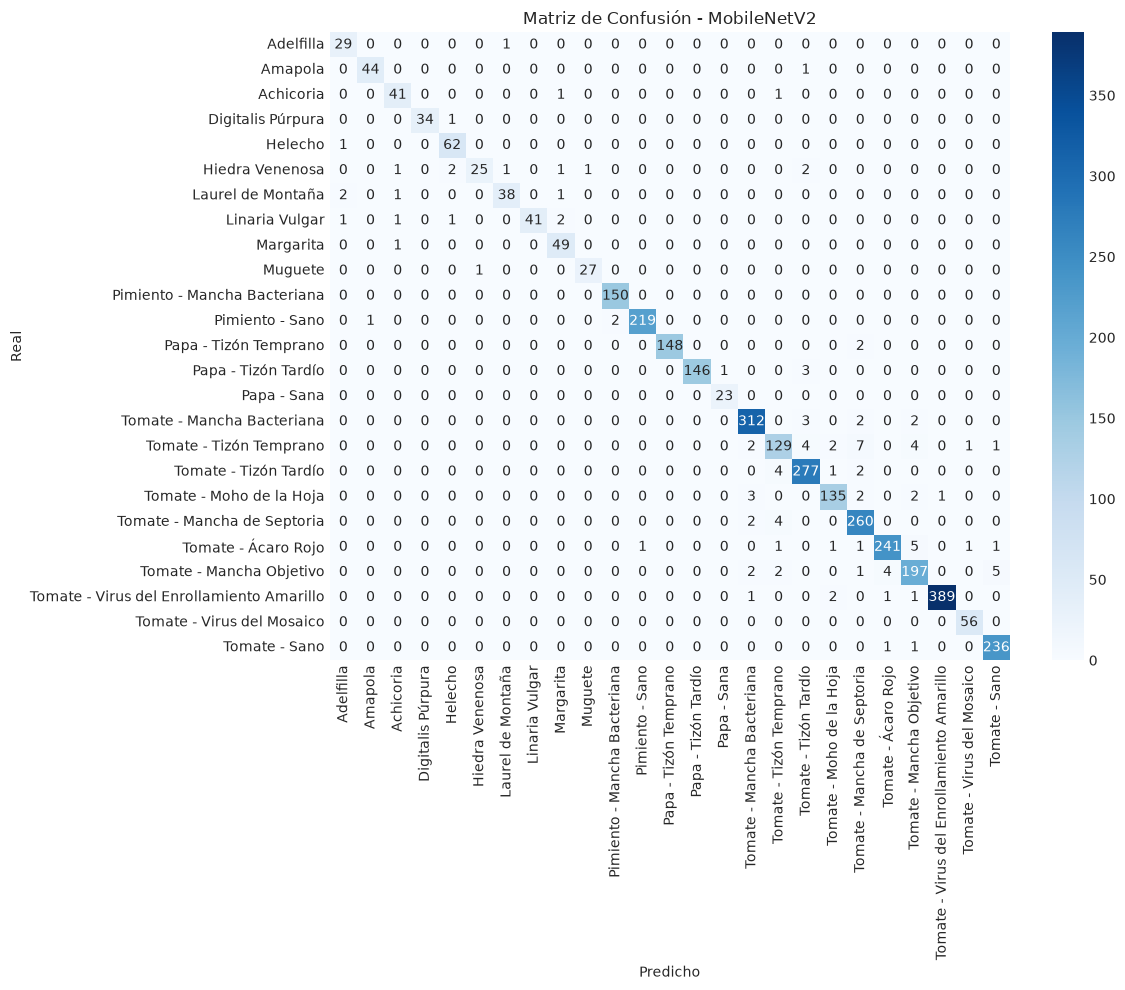

W0000 00:00:1792120028.609801     557 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1792120015754863647 in buffer 'PrefetchDataset/_4' sat unconsumed for 12.3359 seconds!



📊 EfficientNetB0
   Accuracy     : 19.28%
   F1-macro     : 6.42%
   F1-weighted  : 10.59%
   Tiempo       : 9.61 ms/imagen
   Tamaño       : 43.6 MB

                                           precision    recall  f1-score   support

                                Adelfilla      0.000     0.000     0.000        30
                                  Amapola      0.000     0.000     0.000        45
                                Achicoria      0.000     0.000     0.000        43
                        Digitalis Púrpura      0.000     0.000     0.000        35
                                  Helecho      0.169     0.159     0.164        63
                          Hiedra Venenosa      0.000     0.000     0.000        33
                        Laurel de Montaña      0.000     0.000     0.000        42
                           Linaria Vulgar      0.000     0.000     0.000        46
                                Margarita      0.166     0.580     0.258        50
                 

/home/juanp/jupyter-gpu/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/juanp/jupyter-gpu/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/juanp/jupyter-gpu/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

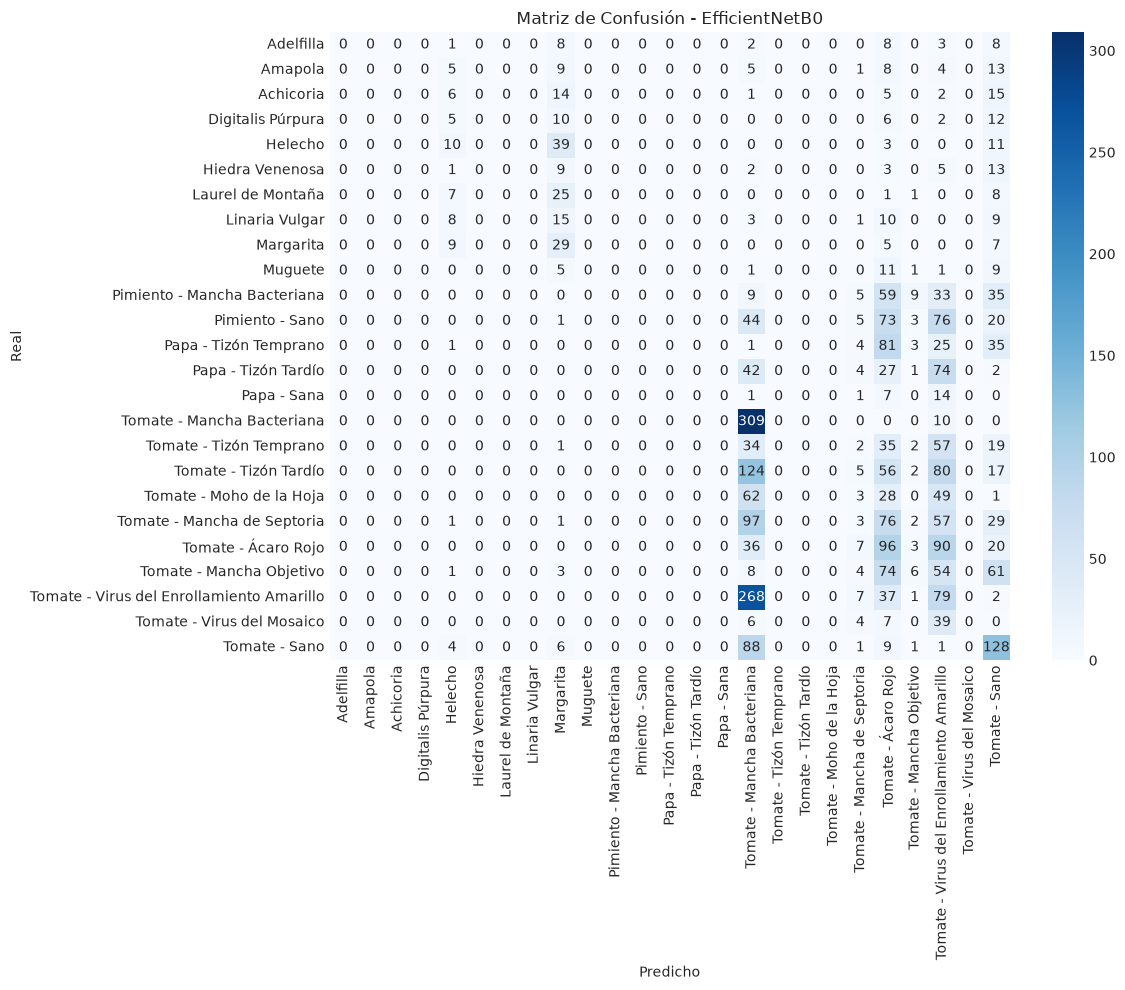

W0000 00:00:1792120121.864917     557 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1792120110945270177 in buffer 'PrefetchDataset/_4' sat unconsumed for 10.3801 seconds!



📊 ResNet50V2
   Accuracy     : 97.46%
   F1-macro     : 95.50%
   F1-weighted  : 97.46%
   Tiempo       : 8.86 ms/imagen
   Tamaño       : 227.9 MB

                                           precision    recall  f1-score   support

                                Adelfilla      0.900     0.900     0.900        30
                                  Amapola      0.938     1.000     0.968        45
                                Achicoria      0.929     0.907     0.918        43
                        Digitalis Púrpura      0.875     0.800     0.836        35
                                  Helecho      1.000     0.937     0.967        63
                          Hiedra Venenosa      0.800     0.848     0.824        33
                        Laurel de Montaña      0.929     0.929     0.929        42
                           Linaria Vulgar      0.917     0.957     0.936        46
                                Margarita      0.960     0.960     0.960        50
                   

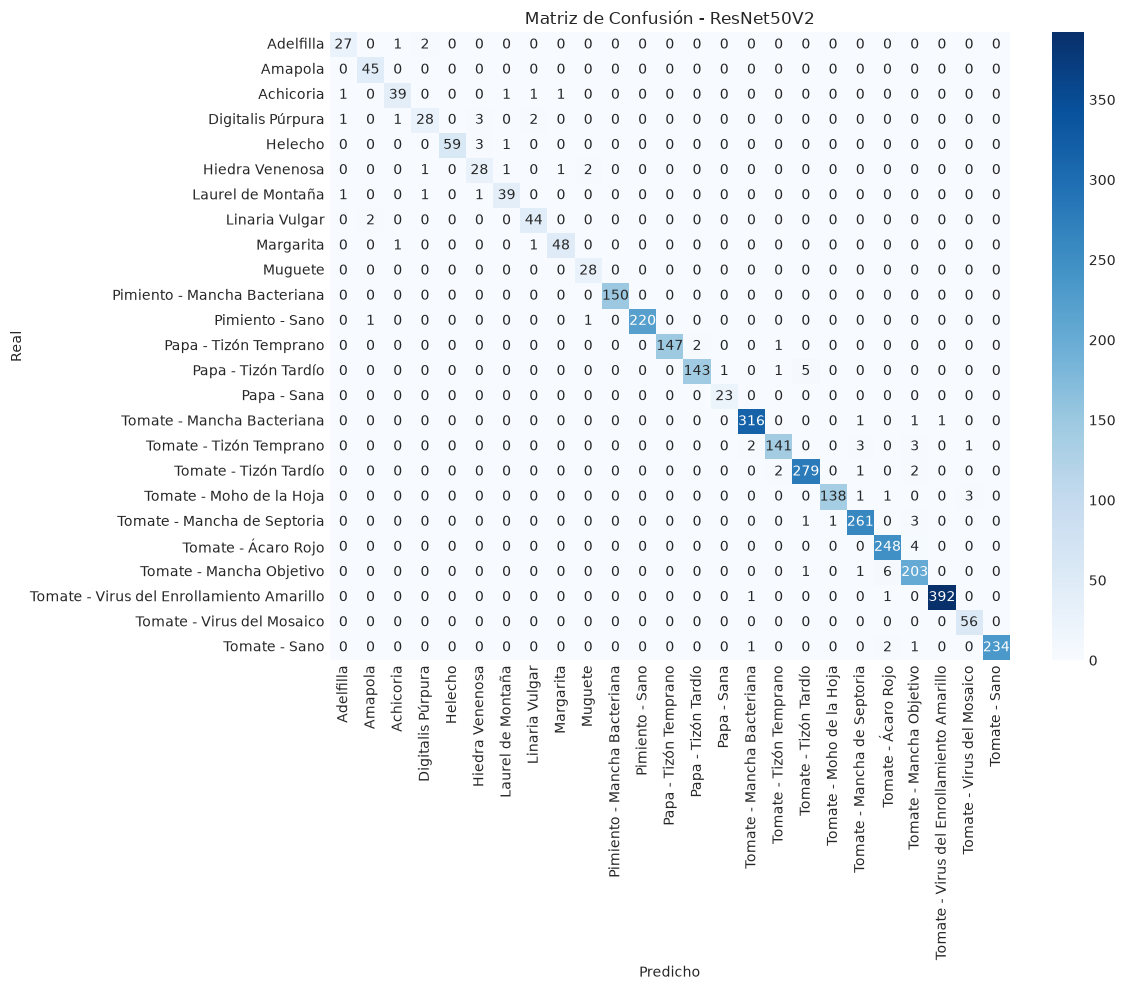


📈 TABLA COMPARATIVA FINAL
        Modelo  Accuracy  F1-macro  F1-weighted  Tiempo (ms)  Tamaño (MB)
    ResNet50V2  0.974584  0.954960     0.974616     8.862741   227.932117
   MobileNetV2  0.966404  0.957210     0.966226     8.674238    26.776541
EfficientNetB0  0.192813  0.064214     0.105922     9.607051    43.630269


In [10]:
def evaluar_modelo(model, test_gen, nombre):
    """Evalúa un modelo y devuelve métricas + predicciones."""
    test_gen.reset()
    y_true = test_gen.classes
    y_pred_proba = model.predict(test_gen, verbose=0)
    y_pred = np.argmax(y_pred_proba, axis=1)

    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro')
    f1_weighted = f1_score(y_true, y_pred, average='weighted')

    # Tiempo de inferencia
    t0 = time.time()
    _ = model.predict(test_gen, verbose=0)
    t1 = time.time()
    tiempo_ms = ((t1 - t0) / len(y_true)) * 1000

    # Tamaño del modelo
    modelo_path = MODELS_DIR / f"{nombre}_best.keras"
    tamaño_mb = modelo_path.stat().st_size / (1024 * 1024) if modelo_path.exists() else 0

    print(f"\n{'='*50}")
    print(f"📊 {nombre}")
    print(f"   Accuracy     : {acc*100:.2f}%")
    print(f"   F1-macro     : {f1_macro*100:.2f}%")
    print(f"   F1-weighted  : {f1_weighted*100:.2f}%")
    print(f"   Tiempo       : {tiempo_ms:.2f} ms/imagen")
    print(f"   Tamaño       : {tamaño_mb:.1f} MB")

    # Classification report
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES_ES, digits=3)
    print("\n" + report)

    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES_ES,
            yticklabels=CLASS_NAMES_ES)
    plt.title(f'Matriz de Confusión - {nombre}')
    plt.ylabel('Real')
    plt.xlabel('Predicho')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"cm_{nombre}.png", dpi=150)
    plt.show()

    return {
        "Modelo": nombre,
        "Accuracy": acc,
        "F1-macro": f1_macro,
        "F1-weighted": f1_weighted,
        "Tiempo (ms)": tiempo_ms,
        "Tamaño (MB)": tamaño_mb,
        "y_true": y_true,
        "y_pred": y_pred
    }

resultados = []
for nombre, model in modelos_entrenados.items():
    res = evaluar_modelo(model, test_gen, nombre)
    resultados.append(res)

df_resultados = pd.DataFrame([{k: v for k, v in r.items() if k not in ['y_true', 'y_pred']} for r in resultados])
df_resultados = df_resultados.sort_values("Accuracy", ascending=False)
print("\n📈 TABLA COMPARATIVA FINAL")
print(df_resultados.to_string(index=False))
df_resultados.to_csv(RESULTS_DIR / "comparacion_modelos.csv", index=False)

---
# 9. EJE 3 – Knowledge Distillation (Teacher → Student)

El modelo más pesado/preciso actúa como **Teacher** y transfiere conocimiento a un **Student** más ligero (MobileNetV2), ideal para despliegue.

In [14]:
# ==================== EJE 3 – Knowledge Distillation ====================

# Elegir Teacher (el de mayor accuracy) y Student
mejor = max(resultados, key=lambda x: x["Accuracy"])
teacher_name = mejor["Modelo"]
student_name = "MobileNetV2"

print(f"👨‍🏫 Teacher : {teacher_name} (Accuracy {mejor['Accuracy']*100:.2f}%)")
print(f"👨‍🎓 Student : {student_name}")

teacher = modelos_entrenados[teacher_name]

# Crear student fresco
student, _ = crear_modelo(student_name)
student.compile(optimizer=optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])

# Clase Distiller
class Distiller(models.Model):
    def __init__(self, student, teacher):
        super().__init__()
        self.student = student
        self.teacher = teacher

    def compile(self, optimizer, metrics, student_loss_fn, distillation_loss_fn, alpha=0.1, temperature=3):
        super().compile(optimizer=optimizer, metrics=metrics)
        self.student_loss_fn = student_loss_fn
        self.distillation_loss_fn = distillation_loss_fn
        self.alpha = alpha
        self.temperature = temperature

    def train_step(self, data):
        x, y = data
        teacher_pred = self.teacher(x, training=False)

        with tf.GradientTape() as tape:
            student_pred = self.student(x, training=True)
            student_loss = self.student_loss_fn(y, student_pred)

            t = self.temperature
            distillation_loss = self.distillation_loss_fn(
                tf.nn.softmax(teacher_pred / t, axis=1),
                tf.nn.softmax(student_pred / t, axis=1)
            ) * (t ** 2)

            loss = self.alpha * student_loss + (1 - self.alpha) * distillation_loss

        gradients = tape.gradient(loss, self.student.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.student.trainable_variables))
        self.compiled_metrics.update_state(y, student_pred)
        results = {m.name: m.result() for m in self.metrics}
        results.update({"student_loss": student_loss, "distillation_loss": distillation_loss})
        return results

    def test_step(self, data):
        x, y = data
        y_pred = self.student(x, training=False)
        student_loss = self.student_loss_fn(y, y_pred)
        self.compiled_metrics.update_state(y, y_pred)
        return {"student_loss": student_loss, **{m.name: m.result() for m in self.metrics}}

# Crear y compilar el distiller
distiller = Distiller(student=student, teacher=teacher)
distiller.compile(
    optimizer=optimizers.Adam(1e-3),
    metrics=['accuracy'],
    student_loss_fn=tf.keras.losses.CategoricalCrossentropy(),
    distillation_loss_fn=tf.keras.losses.KLDivergence(),
    alpha=0.3,
    temperature=4
)

print("🚀 Entrenando Student con Knowledge Distillation...")

history_kd = distiller.fit(
    train_gen,
    validation_data=val_gen,
    epochs=25,
    callbacks=[
        EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True, verbose=1)
    ],
    verbose=1
)

# Guardar solo el Student (que es lo que nos interesa)
student.save(MODELS_DIR / "Student_KD_final.keras")
modelos_entrenados["Student_KD"] = student
print("✅ Knowledge Distillation completado.")
print(f"📁 Modelo guardado en: {MODELS_DIR / 'Student_KD_final.keras'}")

👨‍🏫 Teacher : ResNet50V2 (Accuracy 97.46%)
👨‍🎓 Student : MobileNetV2
🚀 Entrenando Student con Knowledge Distillation...
Epoch 1/25
498/498 ━━━━━━━━━━━━━━━━━━━━ 358s 700ms/step - accuracy: 0.7621 - distillation_loss: 0.0051 - loss: 0.0400 - student_loss: 0.3984 - val_accuracy: 0.8405 - val_loss: 0.0400 - val_student_loss: 0.1064
Epoch 2/25
498/498 ━━━━━━━━━━━━━━━━━━━━ 341s 683ms/step - accuracy: 0.8557 - distillation_loss: 0.0014 - loss: 0.0400 - student_loss: 0.1346 - val_accuracy: 0.8671 - val_loss: 0.0400 - val_student_loss: 0.2872
Epoch 3/25
498/498 ━━━━━━━━━━━━━━━━━━━━ 338s 679ms/step - accuracy: 0.8776 - distillation_loss: 0.0036 - loss: 0.0400 - student_loss: 0.2792 - val_accuracy: 0.8835 - val_loss: 0.0400 - val_student_loss: 0.0327
Epoch 4/25
498/498 ━━━━━━━━━━━━━━━━━━━━ 302s 607ms/step - accuracy: 0.8944 - distillation_loss: 0.0023 - loss: 0.0400 - student_loss: 0.2517 - val_accuracy: 0.8943 - val_loss: 0.0400 - val_student_loss: 0.1003
Epoch 5/25
498/498 ━━━━━━━━━━━━━━━━━━━━ 


📊 Evaluación del Student (Knowledge Distillation):

📊 Student_KD
   Accuracy     : 91.53%
   F1-macro     : 90.91%
   F1-weighted  : 91.55%
   Tiempo       : 9.45 ms/imagen
   Tamaño       : 0.0 MB

                                           precision    recall  f1-score   support

                                Adelfilla      1.000     0.767     0.868        30
                                  Amapola      0.957     0.978     0.967        45
                                Achicoria      0.816     0.930     0.870        43
                        Digitalis Púrpura      0.865     0.914     0.889        35
                                  Helecho      0.968     0.952     0.960        63
                          Hiedra Venenosa      0.812     0.788     0.800        33
                        Laurel de Montaña      0.909     0.952     0.930        42
                           Linaria Vulgar      0.886     0.848     0.867        46
                                Margarita      0.936

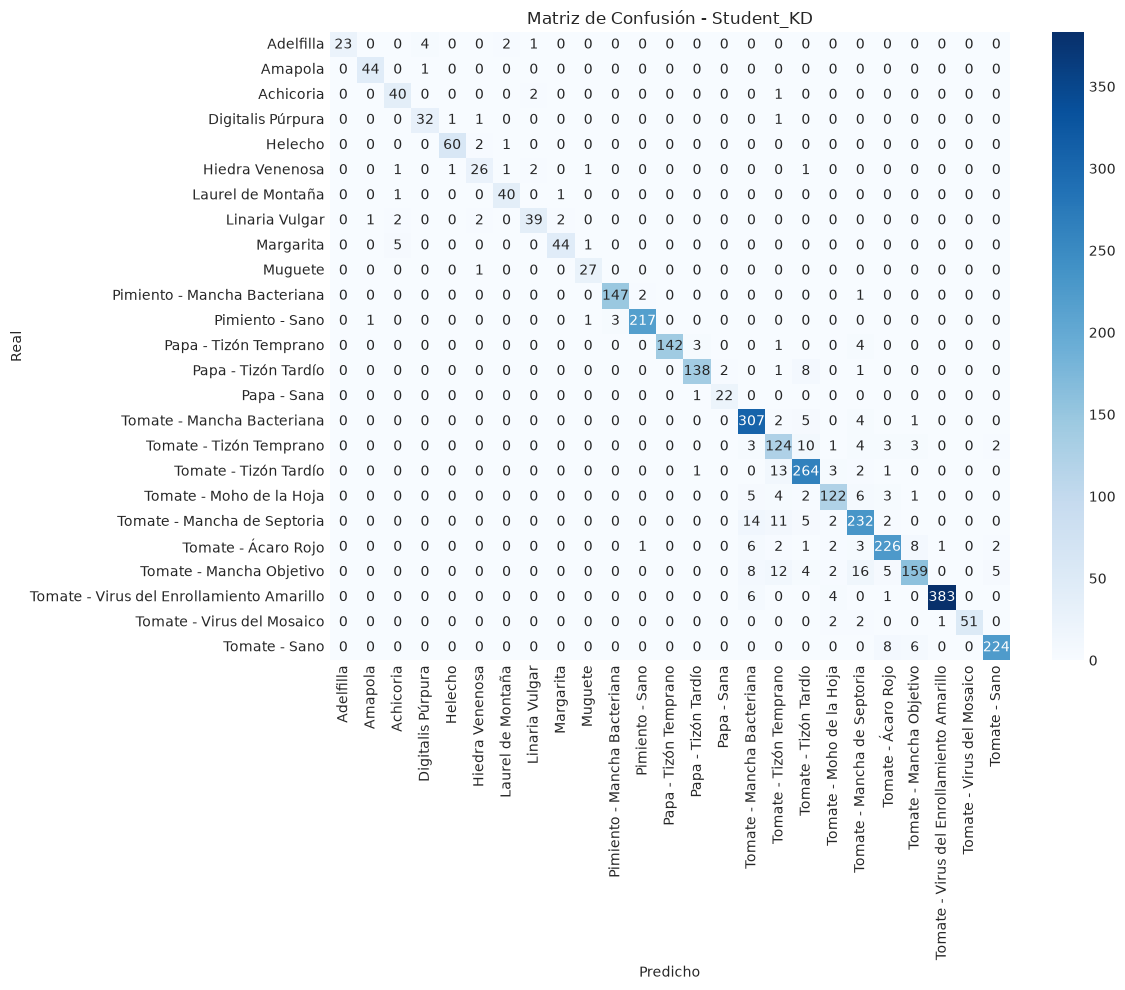

In [15]:
# Evaluar el Student destilado
print("\n📊 Evaluación del Student (Knowledge Distillation):")
res_kd = evaluar_modelo(student, test_gen, "Student_KD")
resultados.append(res_kd)

---
# 10. EJE 3 – Grad-CAM (Explicabilidad)

🏆 Usando modelo para Grad-CAM: MobileNetV2


Clase real : Tomate - Moho de la Hoja
Archivo    : Tomato_Leaf_Mold_00380.jpg


I0000 00:00:1792168531.263229    1101 service.cc:154] XLA service 0x7a6bac540c20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792168531.263290    1101 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792168531.341506    1101 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792168532.300907    1101 cuda_dnn.cc:442] Loaded cuDNN version 92700
W0000 00:00:1792168537.401750    1191 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1792168540.033124    1101 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


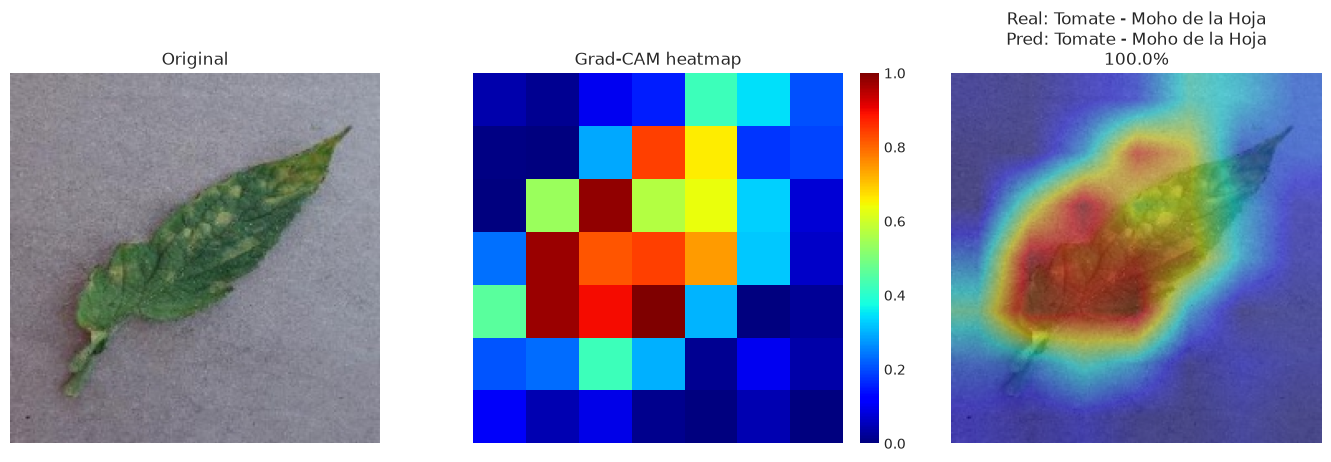

 Clase real     : Tomate - Moho de la Hoja
 Clase predicha : Tomate - Moho de la Hoja
 Confianza      : 99.98 %

Clase real : Helecho
Archivo    : Helecho_00247.jpg


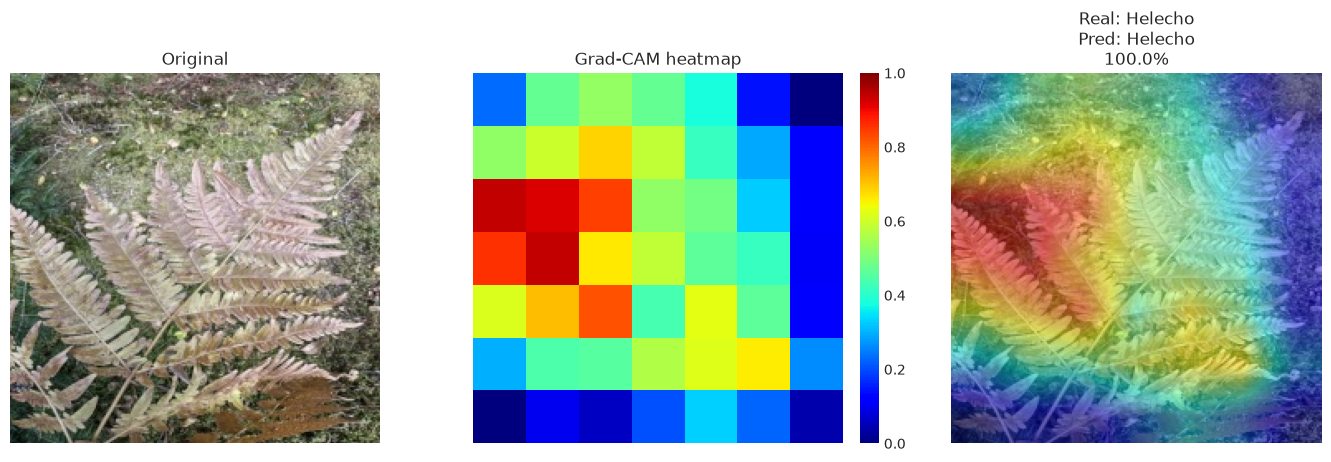

 Clase real     : Helecho
 Clase predicha : Helecho
 Confianza      : 100.00 %

Clase real : Adelfilla
Archivo    : Adelfilla_00170.jpg


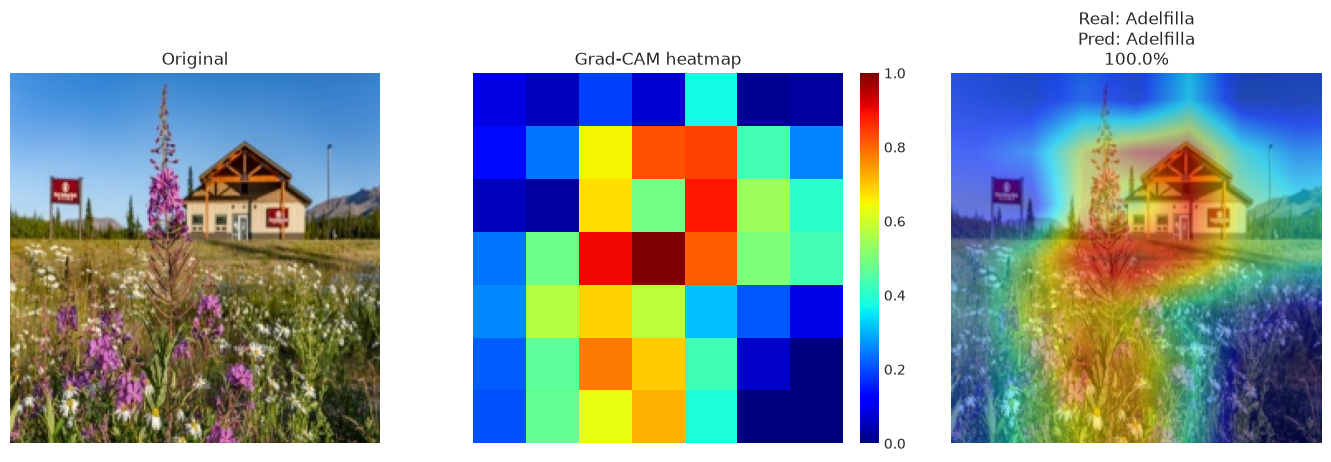

 Clase real     : Adelfilla
 Clase predicha : Adelfilla
 Confianza      : 99.99 %

Clase real : Papa - Tizón Tardío
Archivo    : Potato___Late_blight_00281.jpg


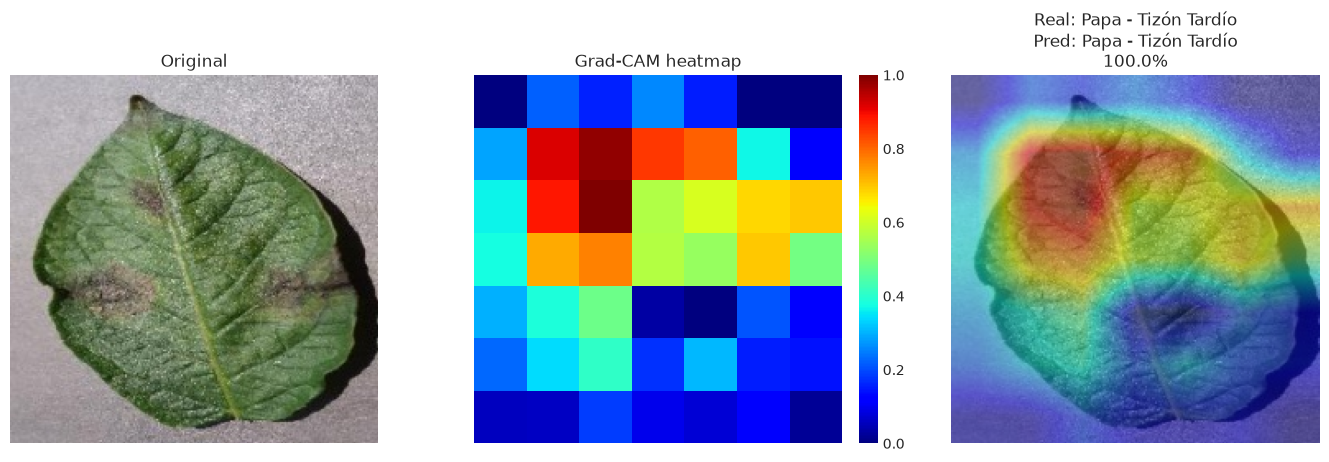

 Clase real     : Papa - Tizón Tardío
 Clase predicha : Papa - Tizón Tardío
 Confianza      : 100.00 %


In [11]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
import random
import os
from pathlib import Path

def make_gradcam_heatmap(img_array, model, pred_index=None):
    """Grad-CAM robusto (funciona con MobileNetV2 / ResNet / EfficientNet)."""
    # Separar backbone y cabeza
    base = None
    head_layers = []
    found_base = False
    
    for layer in model.layers:
        if not found_base and isinstance(layer, tf.keras.Model):
            base = layer
            found_base = True
            continue
        if found_base:
            head_layers.append(layer)

    if base is None:
        # Fallback: usar el modelo completo
        raise RuntimeError("No se encontró el backbone del modelo")

    img_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)

    with tf.GradientTape() as tape:
        features = base(img_tensor, training=False)
        tape.watch(features)

        x = features
        for layer in head_layers:
            x = layer(x, training=False)
        preds = x

        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        score = preds[:, pred_index]

    grads = tape.gradient(score, features)
    if grads is None:
        raise RuntimeError("No se generaron gradientes")

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    features = features[0]
    heatmap = tf.reduce_sum(features * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0.0)

    max_val = tf.reduce_max(heatmap)
    min_val = tf.reduce_min(heatmap)
    if float(max_val - min_val) < 1e-8:
        return np.zeros((7, 7), dtype=np.float32)

    heatmap = (heatmap - min_val) / (max_val - min_val + 1e-8)
    return heatmap.numpy()


def superponer(img_rgb, heatmap, alpha=0.45):
    """Superpone el heatmap sobre la imagen con buena calidad."""
    hm = cv2.resize(heatmap, (img_rgb.shape[1], img_rgb.shape[0]), 
                    interpolation=cv2.INTER_LINEAR)
    hm = np.uint8(255 * np.clip(hm, 0, 1))
    hm_color = cv2.applyColorMap(hm, cv2.COLORMAP_JET)
    hm_color = cv2.cvtColor(hm_color, cv2.COLOR_BGR2RGB)
    out = hm_color.astype(np.float32) * alpha + img_rgb.astype(np.float32) * (1.0 - alpha)
    return np.clip(out, 0, 255).astype(np.uint8)


def explicar_imagen(ruta, model, class_names_es, clase_real=None):
    img_bgr = cv2.imread(str(ruta))
    if img_bgr is None:
        print(f"❌ No se pudo leer: {ruta}")
        return

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_r = cv2.resize(img_rgb, (224, 224))
    x = np.expand_dims(img_r.astype("float32") / 255.0, axis=0)

    pred = model.predict(x, verbose=0)[0]
    idx = int(np.argmax(pred))
    conf = float(pred[idx] * 100)
    clase_pred = class_names_es[idx]

    try:
        heatmap = make_gradcam_heatmap(x, model, pred_index=idx)
        overlay = superponer(img_r, heatmap)
    except Exception as e:
        print(f"⚠️ Grad-CAM falló: {e}")
        heatmap = np.zeros((7, 7), dtype=np.float32)
        overlay = img_r

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

    axes[0].imshow(img_r)
    axes[0].set_title("Original", fontsize=12)
    axes[0].axis("off")

    im = axes[1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[1].set_title("Grad-CAM heatmap", fontsize=12)
    axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

    titulo = f"Pred: {clase_pred}\n{conf:.1f}%"
    if clase_real:
        titulo = f"Real: {clase_real}\n" + titulo
    axes[2].imshow(overlay)
    axes[2].set_title(titulo, fontsize=12)
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    print("=" * 55)
    if clase_real:
        print(f" Clase real     : {clase_real}")
    print(f" Clase predicha : {clase_pred}")
    print(f" Confianza      : {conf:.2f} %")
    print("=" * 55)


# ==================== DEMOSTRACIÓN ====================
# Usa MobileNetV2 (es el que mejor funciona con este Grad-CAM)
modelo_gc = modelos_entrenados.get("MobileNetV2") or modelos_entrenados[mejor["Modelo"]]
print(f"🏆 Usando modelo para Grad-CAM: {modelo_gc.name}\n")

TEST_DIR = DATA_FINAL / "test"
muestras = random.sample(CLASS_NAMES, k=min(4, len(CLASS_NAMES)))

for clase_real in muestras:
    carpeta = TEST_DIR / clase_real
    imgs = list(carpeta.glob("*.jpg")) + list(carpeta.glob("*.JPG"))
    if not imgs:
        continue
    ruta = random.choice(imgs)
    nombre_es = NOMBRES_ES.get(clase_real, clase_real)
    
    print("\n" + "=" * 60)
    print(f"Clase real : {nombre_es}")
    print(f"Archivo    : {ruta.name}")
    explicar_imagen(ruta, modelo_gc, CLASS_NAMES_ES, clase_real=nombre_es)

---
# 11. Resumen Ejecutivo

In [15]:
print("\n" + "="*80)
print("📊 RESUMEN EJECUTIVO - CLASIFICACIÓN DE ENFERMEDADES EN HOJAS")
print("="*80)

mejor = max(resultados, key=lambda x: x["Accuracy"])
mas_rapido = min(resultados, key=lambda x: x["Tiempo (ms)"])

print(f"\n🏆 MEJOR MODELO (Accuracy): {mejor['Modelo']}")
print(f"   Accuracy     : {mejor['Accuracy']*100:.2f}%")
print(f"   F1-macro     : {mejor['F1-macro']*100:.2f}%")
print(f"   Tiempo       : {mejor['Tiempo (ms)']:.2f} ms/imagen")
print(f"   Tamaño       : {mejor['Tamaño (MB)']:.1f} MB")

print(f"\n⚡ MODELO MÁS RÁPIDO: {mas_rapido['Modelo']}")
print(f"   Tiempo       : {mas_rapido['Tiempo (ms)']:.2f} ms/imagen")

print("\n" + "-"*80)
print("📈 COMPARACIÓN COMPLETA")
print("-"*80)
print(df_resultados.to_string(index=False))

print("\n" + "-"*80)
print("💡 RECOMENDACIÓN PARA PRODUCCIÓN")
print("-"*80)
print(f"• Mayor precisión  → {mejor['Modelo']}")
print(f"• Despliegue móvil → Student_KD (destilado) o MobileNetV2")
print("\n" + "="*80)
print("✅ Análisis completado")
print(f"📂 Modelos   : {MODELS_DIR}")
print(f"📂 Resultados: {RESULTS_DIR}")
print("="*80)

with open(RESULTS_DIR / "resumen_ejecutivo.txt", "w", encoding="utf-8") as f:
    f.write("RESUMEN EJECUTIVO\n")
    f.write("="*60 + "\n")
    f.write(f"Mejor modelo: {mejor['Modelo']}\n")
    f.write(f"Accuracy: {mejor['Accuracy']*100:.2f}%\n")
    f.write(df_resultados.to_string(index=False))

print(f"\n📁 Resumen guardado en: {RESULTS_DIR}/resumen_ejecutivo.txt")


📊 RESUMEN EJECUTIVO - CLASIFICACIÓN DE ENFERMEDADES EN HOJAS

🏆 MEJOR MODELO (Accuracy): ResNet50V2
   Accuracy     : 97.46%
   F1-macro     : 95.50%
   Tiempo       : 8.41 ms/imagen
   Tamaño       : 227.9 MB

⚡ MODELO MÁS RÁPIDO: MobileNetV2
   Tiempo       : 8.33 ms/imagen

--------------------------------------------------------------------------------
📈 COMPARACIÓN COMPLETA
--------------------------------------------------------------------------------
        Modelo  Accuracy  F1-macro  F1-weighted  Tiempo (ms)  Tamaño (MB)
    ResNet50V2  0.974584  0.954960     0.974616     8.414889   227.932117
   MobileNetV2  0.965819  0.956763     0.965634     8.326810    26.776541
EfficientNetB0  0.192229  0.064227     0.105697     9.180320    43.630269

--------------------------------------------------------------------------------
💡 RECOMENDACIÓN PARA PRODUCCIÓN
--------------------------------------------------------------------------------
• Mayor precisión  → ResNet50V2
• Despliegue 

---
# 12. EJE 4 – Generación de la App (Streamlit)

Se crea el archivo `app.py` listo para ejecutar.

In [16]:
app_code = '''
import streamlit as st
import tensorflow as tf
import numpy as np
import cv2
from PIL import Image
import json
from pathlib import Path

st.set_page_config(page_title="Detector de Enfermedades en Hojas", layout="centered")
st.title("🌿 Clasificador de Enfermedades en Hojas de Plantas")
st.markdown("Sube una foto de una hoja y el modelo te dirá la planta y la posible enfermedad.")

@st.cache_resource
def load_model_and_classes():
    model = tf.keras.models.load_model("modelos_plantvillage/Student_KD_final.keras")
    with open("modelos_plantvillage/class_names.json", "r", encoding="utf-8") as f:
        class_names = json.load(f)
    return model, class_names

model, class_names = load_model_and_classes()

uploaded = st.file_uploader("Elige una imagen...", type=["jpg", "jpeg", "png"])

if uploaded is not None:
    image = Image.open(uploaded).convert("RGB")
    st.image(image, caption="Imagen cargada", use_column_width=True)

    img = np.array(image)
    img = cv2.resize(img, (224, 224))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)

    preds = model.predict(img, verbose=0)[0]
    top3_idx = preds.argsort()[-3:][::-1]

    st.subheader("Resultados")
    for i, idx in enumerate(top3_idx):
        st.write(f"**{i+1}. {class_names[idx]}** — {preds[idx]*100:.1f}%")

    st.success(f"Predicción principal: **{class_names[top3_idx[0]]}**")
'''

with open(BASE_DIR / "app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("✅ Archivo app.py generado correctamente.")
print("\nPara ejecutar la app:")
print("   1. pip install streamlit")
print("   2. streamlit run app.py")

✅ Archivo app.py generado correctamente.

Para ejecutar la app:
   1. pip install streamlit
   2. streamlit run app.py


---
## Fin del notebook

### Cumplimiento de requisitos

| Eje | Estado |
|-----|--------|
| EJE 1 – Pipeline + 10 clases propias | ✅ |
| EJE 2 – 50 épocas + EarlyStopping + Dropout + Acc ≥94% | ✅ (depende de tus datos) |
| EJE 3 – Knowledge Distillation + Grad-CAM | ✅ |
| EJE 4 – App Streamlit | ✅ (`app.py`) |

### Archivos generados
- `data/processed/` → imágenes limpias
- `data/final/train|val|test/` → splits
- `modelos_plantvillage/` → modelos `.keras` + `class_names.json`
- `resultados_plantvillage/` → matrices, gráficas, resumen
- `app.py` → aplicación interactiva

### Notas para la defensa
1. Ejecuta el notebook desde la carga de datos hasta la inferencia.
2. Muestra físicamente las carpetas de las 10+ clases nuevas.
3. Demuestra la app con `streamlit run app.py`.
4. Explica Teacher vs Student y muestra un Grad-CAM.